# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [3]:
# TODO 1
n_voxels = 512 * 512 * 300
scan_mb = n_voxels * 2 / (1024 ** 2)   # 16 bits = 2 bytes/voxel

# TODO 2
extent_mm = (512 * 0.5, 512 * 0.5, 300 * 1.0)   # (x, y, z) in mm
voxel_mm3 = 0.5 * 0.5 * 1.0

# TODO 3
samples_per_frame = (512 * 300) * 512            # rays (x*z pixels) x samples per ray (y steps)
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 x 0.5 x 1.0 mm). What two things would go wrong in the
radiologist's coronal and sagittal views if the software ignored that (Slides 8-10)?

_Your answer:_

If the software just displayed raw voxel indices without correcting for spacing, two things break in the
coronal and sagittal views (both include z): anatomy looks squashed or stretched vertically, since each
z-step is actually 2x the physical distance of an x/y-step (1.0 mm vs. 0.5 mm). Also any distance measured
along z would be off by that same 2x factor, a lesion's real top-to-bottom extent would read wrong unless
the display scales the z-axis to match, which is exactly what `aspect=ASPECT` is doing below.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

Lesion centroid (z, y, x): (28, 40, 41)


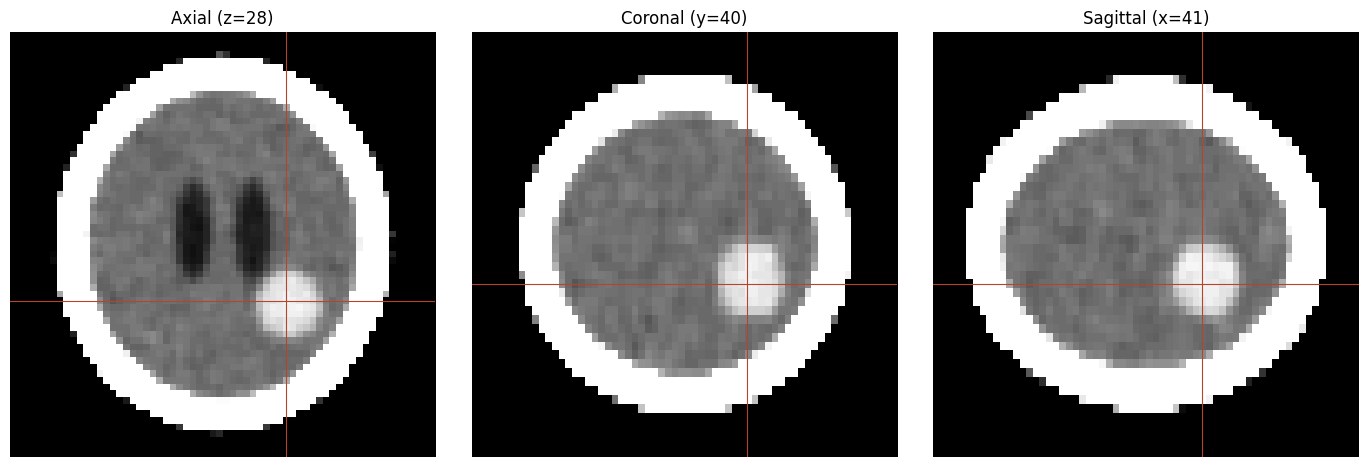

Distance from ground-truth tumour centroid: 2.92 mm


In [4]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
inside_eroded = ndimage.binary_erosion(inside, iterations=3)
candidates = (vol > 55) & (vol < 90) & inside_eroded

# TODO 2
lbl, n_components = ndimage.label(candidates)
sizes = ndimage.sum(candidates, lbl, range(1, n_components + 1))
largest_label = np.argmax(sizes) + 1
lesion = lbl == largest_label
cz, cy, cx = [int(round(v)) for v in ndimage.center_of_mass(lesion)]
print(f"Lesion centroid (z, y, x): ({cz}, {cy}, {cx})")

# TODO 3
W, L = 80, 40
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))

axial = window(vol[cz], W, L)
axes[0].imshow(axial, cmap="gray")
axes[0].axhline(cy, color="#b5432e", lw=0.8); axes[0].axvline(cx, color="#b5432e", lw=0.8)
axes[0].set_title(f"Axial (z={cz})")

coronal = window(vol[:, cy, :], W, L)
axes[1].imshow(coronal, cmap="gray", aspect=ASPECT)
axes[1].axhline(cz, color="#b5432e", lw=0.8); axes[1].axvline(cx, color="#b5432e", lw=0.8)
axes[1].set_title(f"Coronal (y={cy})")

sagittal = window(vol[:, :, cx], W, L)
axes[2].imshow(sagittal, cmap="gray", aspect=ASPECT)
axes[2].axhline(cz, color="#b5432e", lw=0.8); axes[2].axvline(cy, color="#b5432e", lw=0.8)
axes[2].set_title(f"Sagittal (x={cx})")

for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.show()

# TODO 4 (evaluation only)
truth_centroid = ndimage.center_of_mass(labels == 5)
dist_mm = np.sqrt(sum(((a - b) * s) ** 2 for a, b, s in zip((cz, cy, cx), truth_centroid, SPACING)))
print(f"Distance from ground-truth tumour centroid: {dist_mm:.2f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the
overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_

Needed the erosion because right at the brain/skull boundary a single voxel can physically straddle both
tissues, so its HU value ends up blended, not a clean reading of either material. That blended value can
easily land in the tumour's 55-90 window just by coincidence. `binary_fill_holes` gives me the whole brain
interior, but its outer rim is exactly where that blending happens, so eroding it 3 voxels in strips away
the unreliable shell and leaves only voxels I can actually trust. That's the overlapping-intensity-ranges
problem from the lecture, boundary voxels straddle two materials' HU ranges and don't cleanly belong to
either.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_mL,dice
0,45,535,19.26,0.929
1,50,464,16.70,0.994
2,55,431,15.52,0.963
3,60,350,12.60,0.860
4,65,273,9.83,0.741
5,70,170,6.12,0.536


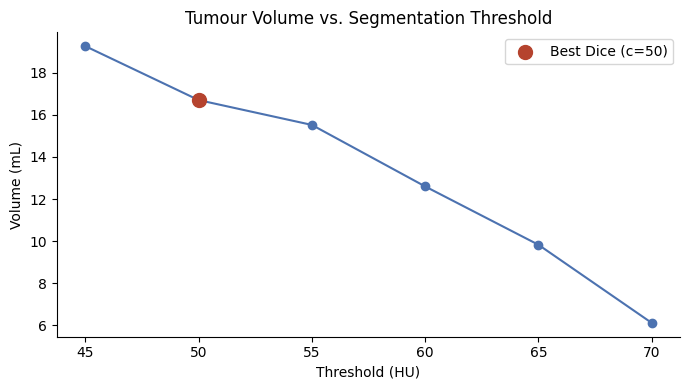

Volume range across plausible thresholds (c=45-60): 12.6 - 19.3 mL
Best single estimate (c=50, highest Dice): 16.7 mL


In [5]:
truth = labels == 5
rows = []
# TODO 1 & 2
for c in [45, 50, 55, 60, 65, 70]:
    mask = vol > c
    lbl2, n2 = ndimage.label(mask)
    comp_label = lbl2[cz, cy, cx]
    region = (lbl2 == comp_label) if comp_label != 0 else np.zeros_like(mask, dtype=bool)
    voxel_count = int(region.sum())
    volume_ml = voxel_count * VOXEL_MM3 / 1000
    dice = 2 * (region & truth).sum() / (region.sum() + truth.sum())
    rows.append({"threshold": c, "voxels": voxel_count, "volume_mL": round(volume_ml, 2), "dice": round(float(dice), 3)})

table = pd.DataFrame(rows)
display(table)

# TODO 3
best_idx = table["dice"].idxmax()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold"], table["volume_mL"], "o-", color="#4C72B0")
ax.scatter([table.loc[best_idx, "threshold"]], [table.loc[best_idx, "volume_mL"]],
           color="#b5432e", s=100, zorder=5, label=f"Best Dice (c={table.loc[best_idx, 'threshold']})")
ax.set_xlabel("Threshold (HU)"); ax.set_ylabel("Volume (mL)")
ax.set_title("Tumour Volume vs. Segmentation Threshold")
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4
plausible = table[table.threshold <= 60]
print(f"Volume range across plausible thresholds (c=45-60): "
      f"{plausible['volume_mL'].min():.1f} - {plausible['volume_mL'].max():.1f} mL")
print(f"Best single estimate (c={table.loc[best_idx, 'threshold']}, highest Dice): "
      f"{table.loc[best_idx, 'volume_mL']:.1f} mL")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour
board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_

Without a Dice score to check against, I'd pick c based on what's anatomically plausible , the HU range
radiologists usually associate with this tumour type and check that the segmented blob stays one coherent
shape across nearby thresholds instead of jumping around. For the board, instead of one number I'd show the
volume-vs-threshold curve itself, or overlay a conservative and a liberal contour on the same slice, so the
surgeon sees the edge as a band of plausible lines rather than one hard line that looks more certain than it
actually is.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

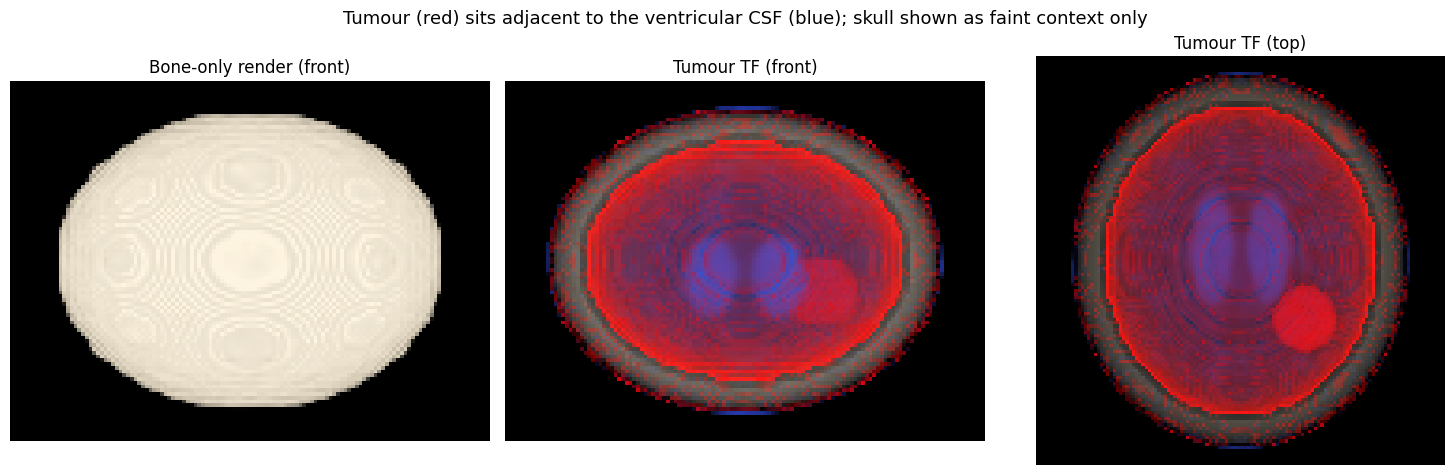

In [6]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (0,     (0, 0, 0), 0.0),
    (4,     (0.2, 0.3, 0.9), 0.05),
    (17,    (0.2, 0.3, 0.9), 0.08),
    (30,    (0.2, 0.3, 0.9), 0.02),
    (44,    (0, 0, 0), 0.0),
    (49,    (1, 0, 0), 0.15),
    (66,    (1, 0, 0), 0.28),
    (77,    (1, 0, 0), 0.15),
    (90,    (0, 0, 0), 0.0),
    (300,   (0, 0, 0), 0.0),
    (400,   (1, 0.95, 0.85), 0.01),
    (1500,  (1, 0.95, 0.85), 0.01),
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
# TODO 1 & 3: bone render | your TF front view | your TF top view
C_bone, A_bone = render(vol, bone_tf, axis=1)
axes[0].imshow(C_bone); axes[0].axis("off"); axes[0].set_title("Bone-only render (front)")

C_front, A_front = render(vol, tumour_tf, axis=1)
axes[1].imshow(C_front); axes[1].axis("off"); axes[1].set_title("Tumour TF (front)")

C_top, A_top = render(vol, tumour_tf, axis=0)
axes[2].imshow(C_top); axes[2].axis("off"); axes[2].set_title("Tumour TF (top)")

# TODO 4: suptitle
fig.suptitle("Tumour (red) sits adjacent to the ventricular CSF (blue); skull shown as faint context only",
             fontsize=13)
plt.tight_layout(); plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31-32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_

That's the overlapping-intensity-ranges problem again. Tumour HU (49-77) sits entirely inside normal brain's
much wider range (22-442, mean ~69 - almost identical to the tumour's own mean of 66.3), so near the skull
boundary, partial-volume blending pushes some totally normal brain voxels into that same 49-77 band. A
segmentation-based render, coloring by which region a voxel was actually assigned to, not by its raw HU -
would fix it. A transfer function alone can't, because it only ever sees one number per voxel and has no way
to know if that number came from tumour tissue or from brain that just happens to share the value.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4-6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

The lesion sits centrally, about 3 mm from where an independent segmentation puts it, and I'd report the
volume as a range - roughly 13-19 mL, best estimate around 16.7 mL, rather than one exact number, since
the threshold you pick genuinely moves the result. I'd open with the MPR view, not the 3D render, because
slicing shows the real boundary against surrounding brain plane by plane, while even a carefully designed 3D
transfer function still bleeds a faint red rim into normal brain just from HU overlap. One thing to flag
about the 3D render: since the tumour's HU range sits entirely inside normal brain's, no intensity-only
transfer function can perfectly separate the two , it's good for showing the tumour's position relative to
the ventricles, not for judging its exact edge.